<a href="https://colab.research.google.com/github/aayushrouniyarcs24-cmd/BIOS-LAB/blob/main/BIOs_lab_Ant_colony.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training hybrid ACO-Q-learning algorithm...
Training episode 1: success rate = 20.0%
Training episode 2: success rate = 50.0%
Training episode 3: success rate = 70.0%
Training episode 4: success rate = 50.0%
Training episode 5: success rate = 60.0%
Training episode 6: success rate = 40.0%

Testing the trained policy...

========== FINAL RESULTS ==========
Robots: 10
Reached target: 0/10
Success rate: 0.00%
No robot reached the target.
Q-table entries: 771
Total runtime: 19.84 seconds


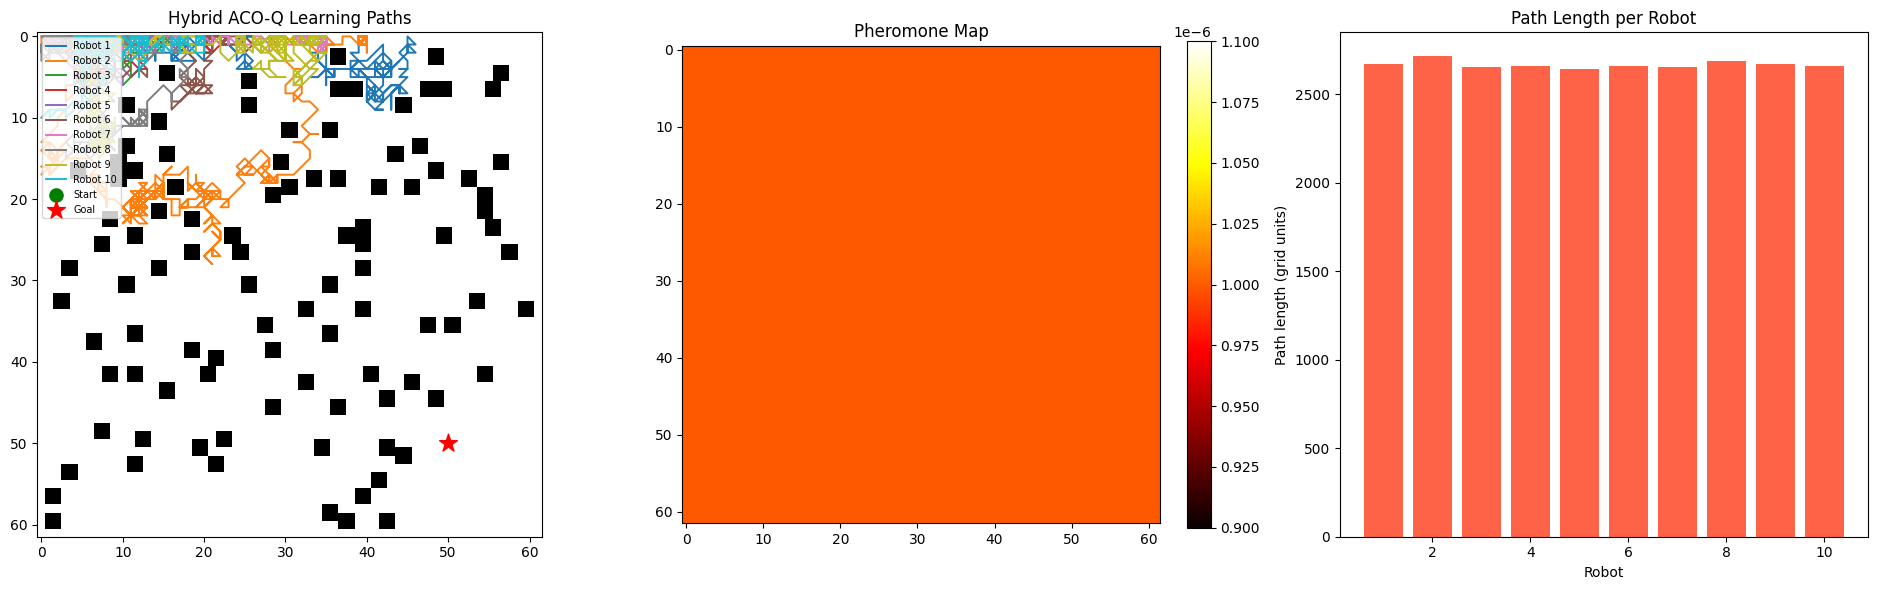

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import random
import time

# ============================================================
# HYBRID ACO + Q-LEARNING FOR SWARM ROBOT PATH PLANNING
# Based on the IEEE ECAI 2025 paper provided by the user
# ============================================================

# -------------------- PARAMETERS -----------------------------

GRID_SIZE = 62
NUM_ROBOTS = 10
NUM_OBSTACLES = 100
MAX_STEPS = 2500
TRAINING_EPISODES = 6

START = (5, 5)
GOAL = (50, 50)

ALPHA = 1.0          # Pheromone influence
BETA = 3.0           # Heuristic influence
EVAPORATION = 0.25   # Pheromone evaporation rate
Q_LEARNING_RATE = 0.2
GAMMA = 0.9
EPSILON = 0.15

PHEROMONE_DEPOSIT = 10.0
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Eight possible movements
ACTIONS = [
    (-1, 0),    # Up
    (1, 0),     # Down
    (0, -1),    # Left
    (0, 1),     # Right
    (-1, -1),   # Up-left
    (-1, 1),    # Up-right
    (1, -1),    # Down-left
    (1, 1)      # Down-right
]


# -------------------- ENVIRONMENT ----------------------------

def create_environment():
    """Create a grid with random 2x2 obstacles."""
    grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)

    count = 0
    attempts = 0

    while count < NUM_OBSTACLES and attempts < NUM_OBSTACLES * 20:
        attempts += 1

        r = random.randint(1, GRID_SIZE - 3)
        c = random.randint(1, GRID_SIZE - 3)

        # Keep the start and goal regions clear
        start_clear = r < 10 and c < 10
        goal_clear = r > 45 and c > 45

        if start_clear or goal_clear:
            continue

        if np.any(grid[r:r+2, c:c+2] == 1):
            continue

        grid[r:r+2, c:c+2] = 1
        count += 1

    return grid


def valid_move(grid, pos, action, occupied=None):
    """Check boundaries, obstacles, diagonal corner-cutting,
    and other robots' current positions."""
    r, c = pos
    dr, dc = action
    nr, nc = r + dr, c + dc

    if not (0 <= nr < GRID_SIZE and 0 <= nc < GRID_SIZE):
        return False

    if grid[nr, nc] == 1:
        return False

    # Do not move diagonally through obstacle corners
    if dr != 0 and dc != 0:
        if grid[r + dr, c] == 1 or grid[r, c + dc] == 1:
            return False

    if occupied is not None and (nr, nc) in occupied:
        return False

    return True


# -------------------- Q-LEARNING -----------------------------

def get_local_state(grid, pos, other_positions):
    """
    Encode the 3x3 neighborhood around a robot.
    0 = free cell
    1 = obstacle or boundary
    2 = another robot

    The nine cells form a compact discrete Q-learning state.
    """
    r, c = pos
    state = []

    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            nr, nc = r + dr, c + dc

            if not (0 <= nr < GRID_SIZE and 0 <= nc < GRID_SIZE):
                value = 1
            elif grid[nr, nc] == 1:
                value = 1
            elif (nr, nc) in other_positions:
                value = 2
            else:
                value = 0

            state.append(value)

    return tuple(state)


def q_update(q_table, state, action_idx, reward, next_state):
    """Bellman Q-learning update."""
    old_value = q_table.get((state, action_idx), 0.0)

    future_values = [
        q_table.get((next_state, a), 0.0)
        for a in range(len(ACTIONS))
    ]

    q_table[(state, action_idx)] = old_value + Q_LEARNING_RATE * (
        reward + GAMMA * max(future_values) - old_value
    )


def choose_q_action(q_table, state, valid_actions, epsilon):
    """Epsilon-greedy action selection."""
    if random.random() < epsilon:
        return random.choice(valid_actions)

    values = [
        q_table.get((state, a), 0.0)
        for a in valid_actions
    ]

    best_value = max(values)
    best_actions = [
        a for a, value in zip(valid_actions, values)
        if value == best_value
    ]

    return random.choice(best_actions)


# -------------------- ACO ------------------------------------

def choose_aco_action(grid, pos, pheromone, occupied):
    """Select a movement using pheromone and goal-distance heuristic."""
    r, c = pos
    candidates = []
    weights = []

    current_distance = np.hypot(GOAL[0] - r, GOAL[1] - c)

    for idx, action in enumerate(ACTIONS):
        if not valid_move(grid, pos, action, occupied):
            continue

        dr, dc = action
        nr, nc = r + dr, c + dc

        next_distance = np.hypot(
            GOAL[0] - nr, GOAL[1] - nc
        )

        # Distance-based heuristic; reward moves toward the goal
        step_distance = np.hypot(dr, dc)
        heuristic = 1.0 / (step_distance + next_distance + 0.1)

        tau = max(pheromone[nr, nc], 1e-6)

        weight = (tau ** ALPHA) * (heuristic ** BETA)

        # Small positive floor preserves exploration
        candidates.append(idx)
        weights.append(max(weight, 1e-12))

    if not candidates:
        return None

    weights = np.asarray(weights, dtype=float)
    probabilities = weights / weights.sum()

    return int(np.random.choice(candidates, p=probabilities))


# -------------------- PHEROMONE UPDATE -----------------------

def update_pheromones(pheromone, paths):
    """Evaporate pheromone and reinforce successful paths."""
    pheromone *= (1.0 - EVAPORATION)

    for path in paths:
        if len(path) < 2:
            continue

        if path[-1] != GOAL:
            continue

        deposit = PHEROMONE_DEPOSIT / max(len(path) - 1, 1)

        for cell in path[1:]:
            pheromone[cell] += deposit

    np.clip(pheromone, 1e-6, 100.0, out=pheromone)


# -------------------- SIMULATION -----------------------------

def run_simulation(grid, q_table, pheromone, training=False):
    """Run one episode with multiple robots."""
    positions = [
        (START[0] + i // 3, START[1] + i % 3)
        for i in range(NUM_ROBOTS)
    ]

    paths = [[pos] for pos in positions]
    reached = [False] * NUM_ROBOTS
    stalled = [0] * NUM_ROBOTS

    for step in range(MAX_STEPS):
        if all(reached):
            break

        # Randomize robot order to reduce movement-order bias
        robot_order = list(range(NUM_ROBOTS))
        random.shuffle(robot_order)

        for i in robot_order:
            if reached[i]:
                continue

            pos = positions[i]

            if pos == GOAL:
                reached[i] = True
                continue

            other_positions = {
                positions[j]
                for j in range(NUM_ROBOTS)
                if j != i and not reached[j]
            }

            valid_actions = [
                a for a in range(len(ACTIONS))
                if valid_move(
                    grid, pos, ACTIONS[a], other_positions
                )
            ]

            if not valid_actions:
                stalled[i] += 1
                continue

            # Use Q-learning in crowded local neighborhoods.
            # Otherwise use ACO.
            local_state = get_local_state(
                grid, pos, other_positions
            )

            nearby_robots = sum(
                1
                for other in other_positions
                if max(
                    abs(other[0] - pos[0]),
                    abs(other[1] - pos[1])
                ) <= 1
            )

            if nearby_robots > 0:
                action_idx = choose_q_action(
                    q_table,
                    local_state,
                    valid_actions,
                    EPSILON if training else 0.0
                )
            else:
                action_idx = choose_aco_action(
                    grid, pos, pheromone, other_positions
                )

                if action_idx is None:
                    stalled[i] += 1
                    continue

            dr, dc = ACTIONS[action_idx]
            next_pos = (pos[0] + dr, pos[1] + dc)

            # Reward for the next state
            if next_pos in other_positions or grid[next_pos] == 1:
                reward = -10.0
            elif next_pos == GOAL:
                reward = 10.0
            else:
                reward = 1.0

            next_others = other_positions - {next_pos}
            next_state = get_local_state(
                grid, next_pos, next_others
            )

            if nearby_robots > 0:
                q_update(
                    q_table, local_state,
                    action_idx, reward, next_state
                )

            positions[i] = next_pos
            paths[i].append(next_pos)
            stalled[i] = 0

            if next_pos == GOAL:
                reached[i] = True

            # Prevent a robot from endlessly circling
            if len(paths[i]) > 40:
                recent = paths[i][-20:]
                if len(set(recent)) <= 4:
                    stalled[i] += 1

        if step % 10 == 0:
            update_pheromones(
                pheromone,
                [paths[i] for i in range(NUM_ROBOTS)
                 if reached[i]]
            )

        if all(reached):
            break

    update_pheromones(
        pheromone,
        [paths[i] for i in range(NUM_ROBOTS) if reached[i]]
    )

    return paths, reached


# -------------------- VISUALIZATION --------------------------

def plot_results(grid, paths, pheromone, reached):
    fig, axes = plt.subplots(1, 3, figsize=(19, 6))

    # Environment and robot paths
    axes[0].imshow(
        grid,
        cmap=ListedColormap(["white", "black"]),
        origin="upper"
    )

    colors = plt.cm.tab10(
        np.linspace(0, 1, NUM_ROBOTS)
    )

    for i, path in enumerate(paths):
        coords = np.array(path)
        axes[0].plot(
            coords[:, 1], coords[:, 0],
            color=colors[i], linewidth=1.4,
            label=f"Robot {i+1}"
        )

    axes[0].scatter(
        START[1], START[0],
        c="green", marker="o", s=90, label="Start"
    )
    axes[0].scatter(
        GOAL[1], GOAL[0],
        c="red", marker="*", s=180, label="Goal"
    )

    axes[0].set_title("Hybrid ACO-Q Learning Paths")
    axes[0].legend(fontsize=7, loc="upper left")

    # Pheromone heatmap
    im = axes[1].imshow(pheromone, cmap="hot", origin="upper")
    axes[1].set_title("Pheromone Map")
    plt.colorbar(im, ax=axes[1], fraction=0.046)

    # Success and path lengths
    lengths = [
        sum(
            np.hypot(
                path[k+1][0] - path[k][0],
                path[k+1][1] - path[k][1]
            )
            for k in range(len(path) - 1)
        )
        for path in paths
    ]

    colors_bar = [
        "seagreen" if reached[i] else "tomato"
        for i in range(NUM_ROBOTS)
    ]

    axes[2].bar(
        range(1, NUM_ROBOTS + 1),
        lengths,
        color=colors_bar
    )
    axes[2].set_xlabel("Robot")
    axes[2].set_ylabel("Path length (grid units)")
    axes[2].set_title("Path Length per Robot")

    plt.tight_layout()
    plt.show()


# -------------------- MAIN -----------------------------------

def main():
    grid = create_environment()

    # Initialize pheromone levels
    pheromone = np.ones(
        (GRID_SIZE, GRID_SIZE), dtype=float
    )

    # Each key represents (local state, action index)
    q_table = {}

    print("Training hybrid ACO-Q-learning algorithm...")
    start_time = time.time()

    for episode in range(TRAINING_EPISODES):
        paths, reached = run_simulation(
            grid, q_table, pheromone, training=True
        )

        success = 100 * sum(reached) / NUM_ROBOTS
        print(
            f"Training episode {episode + 1}: "
            f"success rate = {success:.1f}%"
        )

    print("\nTesting the trained policy...")
    test_paths, test_reached = run_simulation(
        grid, q_table, pheromone, training=False
    )

    elapsed = time.time() - start_time

    lengths = [
        sum(
            np.hypot(
                path[k+1][0] - path[k][0],
                path[k+1][1] - path[k][1]
            )
            for k in range(len(path) - 1)
        )
        for path in test_paths
    ]

    success_count = sum(test_reached)
    successful_lengths = [
        lengths[i]
        for i in range(NUM_ROBOTS)
        if test_reached[i]
    ]

    print("\n========== FINAL RESULTS ==========")
    print(f"Robots: {NUM_ROBOTS}")
    print(f"Reached target: {success_count}/{NUM_ROBOTS}")
    print(
        f"Success rate: "
        f"{100 * success_count / NUM_ROBOTS:.2f}%"
    )

    if successful_lengths:
        print(
            f"Average successful path length: "
            f"{np.mean(successful_lengths):.2f}"
        )
    else:
        print("No robot reached the target.")

    print(f"Q-table entries: {len(q_table)}")
    print(f"Total runtime: {elapsed:.2f} seconds")

    plot_results(grid, test_paths, pheromone, test_reached)


if __name__ == "__main__":
    main()


HYBRID ACO + Q-LEARNING SWARM ROBOT SIMULATION
Obstacles placed: 100

TRAINING
Episode 01/50 | Reached: 10/10 | Success: 100.0% | Epsilon: 0.350
Episode 02/50 | Reached: 9/10 | Success: 90.0% | Epsilon: 0.336
Episode 03/50 | Reached: 10/10 | Success: 100.0% | Epsilon: 0.323
Episode 04/50 | Reached: 9/10 | Success: 90.0% | Epsilon: 0.310
Episode 05/50 | Reached: 10/10 | Success: 100.0% | Epsilon: 0.297
Episode 06/50 | Reached: 10/10 | Success: 100.0% | Epsilon: 0.285
Episode 07/50 | Reached: 8/10 | Success: 80.0% | Epsilon: 0.274
Episode 08/50 | Reached: 10/10 | Success: 100.0% | Epsilon: 0.263
Episode 09/50 | Reached: 10/10 | Success: 100.0% | Epsilon: 0.252
Episode 10/50 | Reached: 10/10 | Success: 100.0% | Epsilon: 0.242
Episode 11/50 | Reached: 10/10 | Success: 100.0% | Epsilon: 0.233
Episode 12/50 | Reached: 9/10 | Success: 90.0% | Epsilon: 0.223
Episode 13/50 | Reached: 10/10 | Success: 100.0% | Epsilon: 0.214
Episode 14/50 | Reached: 10/10 | Success: 100.0% | Epsilon: 0.206
Episo

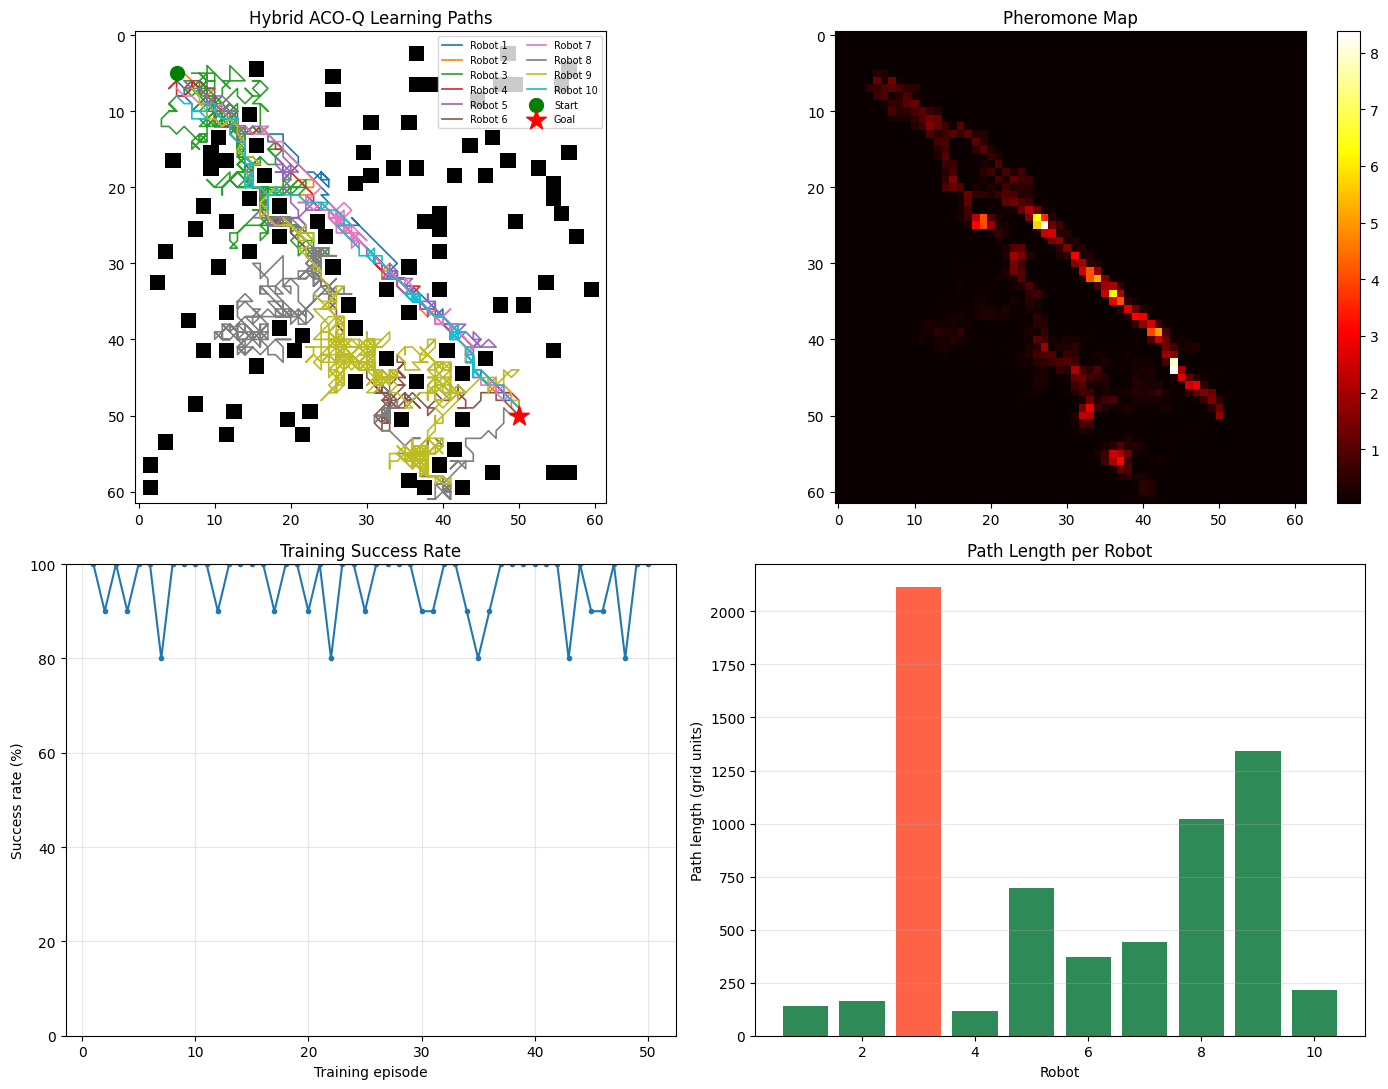

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import defaultdict
import random
import time

# ============================================================
# HYBRID ACO + Q-LEARNING FOR SWARM ROBOT PATH PLANNING
# Grid-based simulation inspired by the IEEE ECAI 2025 paper
# ============================================================

# -------------------- CONFIGURATION -------------------------

GRID_SIZE = 62
NUM_ROBOTS = 10
NUM_OBSTACLES = 100

START = (5, 5)
GOAL = (50, 50)

TRAINING_EPISODES = 50
MAX_STEPS = 1800

# ACO parameters
ALPHA = 1.0
BETA = 3.0
EVAPORATION = 0.08
INITIAL_PHEROMONE = 1.0
PHEROMONE_DEPOSIT = 40.0

# Q-learning parameters
LEARNING_RATE = 0.2
GAMMA = 0.9
EPSILON_START = 0.35
EPSILON_MIN = 0.03
EPSILON_DECAY = 0.96

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Eight possible movements
ACTIONS = [
    (-1, 0), (1, 0), (0, -1), (0, 1),
    (-1, -1), (-1, 1), (1, -1), (1, 1)
]


# ============================================================
# 1. ENVIRONMENT GENERATION
# ============================================================

def create_environment():
    grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=np.uint8)

    # Keep the starting and goal regions free of obstacles.
    protected = np.zeros_like(grid, dtype=bool)
    protected[:12, :12] = True
    protected[45:57, 45:57] = True

    placed = 0
    attempts = 0

    while placed < NUM_OBSTACLES and attempts < 10000:
        attempts += 1
        r = random.randint(1, GRID_SIZE - 3)
        c = random.randint(1, GRID_SIZE - 3)

        if np.any(grid[r:r+2, c:c+2]):
            continue

        if np.any(protected[r:r+2, c:c+2]):
            continue

        grid[r:r+2, c:c+2] = 1
        placed += 1

    print(f"Obstacles placed: {placed}")
    return grid


def initial_positions():
    return [
        (START[0] + i // 3, START[1] + i % 3)
        for i in range(NUM_ROBOTS)
    ]


# ============================================================
# 2. COLLISION AND MOVEMENT VALIDATION
# ============================================================

def valid_move(grid, pos, action, occupied):
    r, c = pos
    dr, dc = action
    nr, nc = r + dr, c + dc

    if not (0 <= nr < GRID_SIZE and 0 <= nc < GRID_SIZE):
        return False

    if grid[nr, nc] == 1:
        return False

    if (nr, nc) in occupied:
        return False

    # Prevent diagonal corner-cutting through obstacles.
    if dr != 0 and dc != 0:
        if grid[r + dr, c] == 1:
            return False
        if grid[r, c + dc] == 1:
            return False

    return True


# ============================================================
# 3. LOCAL STATE FOR Q-LEARNING
# ============================================================

def local_state(grid, pos, other_positions):
    """
    Encode the 3x3 neighborhood:
    0 = free cell
    1 = obstacle or boundary
    2 = another robot
    """
    r, c = pos
    state = []

    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            nr, nc = r + dr, c + dc

            if not (0 <= nr < GRID_SIZE and 0 <= nc < GRID_SIZE):
                value = 1
            elif grid[nr, nc] == 1:
                value = 1
            elif (nr, nc) in other_positions:
                value = 2
            else:
                value = 0

            state.append(value)

    return tuple(state)


# ============================================================
# 4. Q-LEARNING FUNCTIONS
# ============================================================

def choose_q_action(q_table, state, valid_actions, epsilon):
    # Exploration
    if random.random() < epsilon:
        return random.choice(valid_actions)

    # Exploitation
    values = [
        q_table[(state, action)]
        for action in valid_actions
    ]

    best_value = max(values)

    best_actions = [
        action
        for action, value in zip(valid_actions, values)
        if np.isclose(value, best_value)
    ]

    return random.choice(best_actions)


def update_q(q_table, state, action, reward,
             next_state, next_actions, terminal=False):
    old_value = q_table[(state, action)]

    if terminal or not next_actions:
        future_value = 0.0
    else:
        future_value = max(
            q_table[(next_state, a)]
            for a in next_actions
        )

    target = reward + GAMMA * future_value

    q_table[(state, action)] = (
        old_value
        + LEARNING_RATE * (target - old_value)
    )


# ============================================================
# 5. ANT COLONY OPTIMIZATION
# ============================================================

def heuristic(pos, next_pos):
    """Goal-directed heuristic."""
    distance = np.hypot(
        GOAL[0] - next_pos[0],
        GOAL[1] - next_pos[1]
    )
    return 1.0 / (distance + 0.1)


def choose_aco_action(grid, pos, pheromone, occupied):
    candidates = []
    weights = []

    for action_index, action in enumerate(ACTIONS):
        if not valid_move(grid, pos, action, occupied):
            continue

        dr, dc = action
        next_pos = (pos[0] + dr, pos[1] + dc)

        tau = max(pheromone[next_pos], 1e-8)
        eta = heuristic(pos, next_pos)

        weight = (tau ** ALPHA) * (eta ** BETA)

        candidates.append(action_index)
        weights.append(weight)

    if not candidates:
        return None

    weights = np.asarray(weights, dtype=float)

    if not np.all(np.isfinite(weights)) or weights.sum() <= 0:
        return random.choice(candidates)

    probabilities = weights / weights.sum()

    return int(np.random.choice(candidates, p=probabilities))


def evaporate_pheromones(pheromone):
    pheromone *= (1.0 - EVAPORATION)

    # Keep a small positive baseline.
    np.maximum(
        pheromone,
        INITIAL_PHEROMONE * 0.05,
        out=pheromone
    )


def deposit_pheromones(pheromone, paths, reached):
    """Reinforce successful paths; shorter paths deposit more."""
    for path, success in zip(paths, reached):
        if not success or len(path) < 2:
            continue

        deposit = PHEROMONE_DEPOSIT / (len(path) - 1)

        for cell in path:
            pheromone[cell] += deposit

    np.clip(pheromone, 1e-6, 1e5, out=pheromone)


# ============================================================
# 6. RUN ONE SIMULATION EPISODE
# ============================================================

def run_episode(grid, q_table, pheromone,
                training=True, epsilon=EPSILON_START):

    positions = initial_positions()
    paths = [[p] for p in positions]
    reached = [p == GOAL for p in positions]

    for step in range(MAX_STEPS):
        if all(reached):
            break

        # Random scheduling avoids fixed robot priority.
        order = list(range(NUM_ROBOTS))
        random.shuffle(order)

        for i in order:
            if reached[i]:
                continue

            pos = positions[i]

            occupied = {
                positions[j]
                for j in range(NUM_ROBOTS)
                if j != i and not reached[j]
            }

            valid_actions = [
                a for a, action in enumerate(ACTIONS)
                if valid_move(grid, pos, action, occupied)
            ]

            if not valid_actions:
                continue

            state = local_state(grid, pos, occupied)

            nearby = any(
                max(abs(p[0] - pos[0]), abs(p[1] - pos[1])) <= 1
                for p in occupied
            )

            # Hybrid decision:
            # Q-learning in crowded states; ACO elsewhere.
            if nearby:
                action_index = choose_q_action(
                    q_table, state, valid_actions,
                    epsilon if training else 0.0
                )
            else:
                action_index = choose_aco_action(
                    grid, pos, pheromone, occupied
                )

                if action_index is None:
                    continue

            dr, dc = ACTIONS[action_index]
            next_pos = (pos[0] + dr, pos[1] + dc)

            old_distance = np.hypot(
                GOAL[0] - pos[0],
                GOAL[1] - pos[1]
            )

            new_distance = np.hypot(
                GOAL[0] - next_pos[0],
                GOAL[1] - next_pos[1]
            )

            # Goal-directed reward
            if next_pos == GOAL:
                reward = 100.0
            else:
                reward = 2.0 * (
                    old_distance - new_distance
                ) - 0.5

                # Penalize recent loops
                if next_pos in paths[i][-15:]:
                    reward -= 3.0

            positions[i] = next_pos
            paths[i].append(next_pos)

            if next_pos == GOAL:
                reached[i] = True

            # Learn only in crowded states.
            if nearby and training:
                next_occupied = {
                    positions[j]
                    for j in range(NUM_ROBOTS)
                    if j != i and not reached[j]
                }

                next_state = local_state(
                    grid, next_pos, next_occupied
                )

                next_actions = [
                    a for a, action in enumerate(ACTIONS)
                    if valid_move(
                        grid, next_pos, action, next_occupied
                    )
                ]

                update_q(
                    q_table,
                    state,
                    action_index,
                    reward,
                    next_state,
                    next_actions,
                    terminal=(next_pos == GOAL)
                )

        if step % 50 == 0:
            evaporate_pheromones(pheromone)

    deposit_pheromones(pheromone, paths, reached)

    return paths, reached


# ============================================================
# 7. PERFORMANCE MEASUREMENT
# ============================================================

def path_length(path):
    if len(path) < 2:
        return 0.0

    points = np.asarray(path, dtype=float)
    differences = np.diff(points, axis=0)

    return float(
        np.sum(
            np.sqrt(np.sum(differences ** 2, axis=1))
        )
    )


def evaluate(paths, reached):
    lengths = [path_length(p) for p in paths]

    successful_lengths = [
        lengths[i]
        for i in range(len(paths))
        if reached[i]
    ]

    return {
        "success_count": sum(reached),
        "success_rate": 100.0 * sum(reached) / len(reached),
        "average_successful_length": (
            np.mean(successful_lengths)
            if successful_lengths else None
        ),
        "lengths": lengths
    }


# ============================================================
# 8. VISUALIZATION
# ============================================================

def plot_results(grid, paths, reached, pheromone, history):
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))

    # Robot paths
    ax = axes[0, 0]
    ax.imshow(
        grid,
        cmap=ListedColormap(["white", "black"]),
        origin="upper",
        interpolation="nearest"
    )

    colors = plt.cm.tab10(np.linspace(0, 1, NUM_ROBOTS))

    for i, path in enumerate(paths):
        points = np.asarray(path)

        ax.plot(
            points[:, 1],
            points[:, 0],
            color=colors[i],
            linewidth=1.2,
            label=f"Robot {i+1}"
        )

    ax.scatter(
        START[1], START[0],
        c="green", s=100, label="Start", zorder=5
    )
    ax.scatter(
        GOAL[1], GOAL[0],
        c="red", marker="*", s=220, label="Goal", zorder=5
    )

    ax.set_title("Hybrid ACO-Q Learning Paths")
    ax.legend(fontsize=7, ncol=2)

    # Pheromone heatmap
    ax = axes[0, 1]
    im = ax.imshow(pheromone, cmap="hot", origin="upper")
    ax.set_title("Pheromone Map")
    plt.colorbar(im, ax=ax, fraction=0.046)

    # Training progress
    ax = axes[1, 0]
    ax.plot(
        range(1, len(history) + 1),
        history,
        marker="o",
        markersize=3
    )
    ax.set_xlabel("Training episode")
    ax.set_ylabel("Success rate (%)")
    ax.set_ylim(0, 100)
    ax.set_title("Training Success Rate")
    ax.grid(alpha=0.3)

    # Path lengths
    ax = axes[1, 1]
    lengths = [path_length(p) for p in paths]

    bar_colors = [
        "seagreen" if reached[i] else "tomato"
        for i in range(NUM_ROBOTS)
    ]

    ax.bar(
        range(1, NUM_ROBOTS + 1),
        lengths,
        color=bar_colors
    )
    ax.set_xlabel("Robot")
    ax.set_ylabel("Path length (grid units)")
    ax.set_title("Path Length per Robot")
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


# ============================================================
# 9. MAIN
# ============================================================

def main():
    print("=" * 55)
    print("HYBRID ACO + Q-LEARNING SWARM ROBOT SIMULATION")
    print("=" * 55)

    grid = create_environment()

    pheromone = np.full(
        (GRID_SIZE, GRID_SIZE),
        INITIAL_PHEROMONE,
        dtype=float
    )

    q_table = defaultdict(float)
    history = []

    start_time = time.time()

    print("\nTRAINING")

    epsilon = EPSILON_START

    for episode in range(TRAINING_EPISODES):
        paths, reached = run_episode(
            grid,
            q_table,
            pheromone,
            training=True,
            epsilon=epsilon
        )

        metrics = evaluate(paths, reached)
        history.append(metrics["success_rate"])

        print(
            f"Episode {episode + 1:02d}/"
            f"{TRAINING_EPISODES} | "
            f"Reached: {metrics['success_count']}/"
            f"{NUM_ROBOTS} | "
            f"Success: {metrics['success_rate']:.1f}% | "
            f"Epsilon: {epsilon:.3f}"
        )

        epsilon = max(
            EPSILON_MIN,
            epsilon * EPSILON_DECAY
        )

    print("\nTESTING")

    test_paths, test_reached = run_episode(
        grid,
        q_table,
        pheromone,
        training=False,
        epsilon=0.0
    )

    metrics = evaluate(test_paths, test_reached)
    elapsed = time.time() - start_time

    print("\nFINAL RESULTS")
    print("-" * 40)
    print(f"Robots                : {NUM_ROBOTS}")
    print(f"Reached target        : {metrics['success_count']}")
    print(f"Success rate          : {metrics['success_rate']:.2f}%")
    print(f"Q-table entries       : {len(q_table)}")

    if metrics["average_successful_length"] is not None:
        print(
            "Average successful path length: "
            f"{metrics['average_successful_length']:.2f}"
        )
    else:
        print("Average successful path length: N/A")

    print(f"Runtime               : {elapsed:.2f} seconds")

    for i, length in enumerate(metrics["lengths"]):
        status = "SUCCESS" if test_reached[i] else "FAILED"
        print(
            f"Robot {i+1:02d}: {status:7s} "
            f"Path length = {length:.2f}"
        )

    plot_results(
        grid,
        test_paths,
        test_reached,
        pheromone,
        history
    )


if __name__ == "__main__":
    main()
